# $\zeta(2)$: historical constructions

Exact rational approximants, sampled at $N=10,20,\ldots,500$.
Here $\delta_N=-1-\log|\zeta(2)-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\zeta(2)-p_N/q_N|$, with $p_N/q_N$ reduced.
Published bounds and measured finite-depth exponents are distinct.
Source-index offsets and the staircase parameter are stated below.

**Runtime skips (120 seconds per example):** Giraudin (2026). No depth-500 values are shown for these runs.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    apery_seeds, zudilin_zeta23_seeds, zudilin_zeta23_readout,
    dvornicich_viola_zeta2, dvornicich_viola_zeta2_seeds,
    dvornicich_viola_zeta2_path, staircase_states,
)

DEPTHS = list(range(10, 501, 10))
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
results, accuracy = {}, {}


def measure(approximant):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 128):
        error = abs(arb(2).zeta() - arb(p) / q)
        assert error > 0 and q > 1
        return (float((-1 - error.log() / arb(q).log()).mid()),
                float((-error.log() / arb(10).log()).mid()))

## 1. Apéry (1978/1979)

[Paper, pp. 12–13](https://www.numdam.org/article/AST_1979__61__11_0.pdf).
$\mu(\zeta(2))\le 11.85078\ldots$.

**CMF:** ${}_3F_2(1)$, rank 2. **Start:** $(-2,-2,3;1,1)$.
**Direction:** $(-1,-1,1;0,0)$. Source index $N$ uses $N-2$ steps.
**Readout:** $(PW)_0/(QW)_0$, with $P=(125/4,79/2)$, $Q=(19,24)$;
these recover the source sequences $b_N/a_N$.

In [5]:
cmf = pFq(3, 2, 1)
start = {x0: -2, x1: -2, x2: 3, y0: 1, y1: 1}
trajectory = {x0: -1, x1: -1, x2: 1, y0: 0, y1: 0}
P, Q = apery_seeds(2)
walks = cmf.walk(trajectory, [N - 2 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Apéry (1979)"] = (DEPTHS, deltas)
accuracy["Apéry (1979)"] = [value[1] for value in measurements]
print(f"delta at source N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at source N = 500: 0.103550179820


## 2. Beukers (1979)

[Paper](https://doi.org/10.1112/blms/11.3.268).
$I_n=\int_{[0,1]^2}[x(1-x)y(1-y)]^n(1-xy)^{-n-1}\,dx\,dy$;
the bound is $11.85078\ldots$.
The start is at integral index 2, so $n=N+2$.

**CMF:** dual ${}_3F_2(1)$, rank 2. **Start:** $(3,3,3;6,6)$.
**Direction:** $(1,1,1;2,2)$. $N$ is the walk length.
**Readout:** $(533W_{00}+125W_{10})/(324W_{00}+76W_{10})$.

In [7]:
cmf = pFq(3, 2, 1).dual()
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) /
                (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Beukers (1979)"] = (DEPTHS, deltas)
accuracy["Beukers (1979)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.099556310096


## 3. Dvornicich–Viola (1987; proceedings 1990)

[Construction, p. 100](https://www.numdam.org/article/AIF_1993__43_1_85_0.pdf).
With $\psi=x(1-x)y(1-y)/(1-xy)$,
$S(e)=\int_{[0,1]^2}\psi^{e_0}(1-11\psi)^{e_1}(1-12\psi)^{e_2}\,dx\,dy/(1-xy)$.
Published bound: $10.0298$.

**CMF:** custom moment field, rank 6. **Start:** $(0,0,0)$.
**Path:** $(2\lfloor18.53172m\rfloor,2\lfloor1.38784m\rfloor,2m)$.
**Readout:** $-C_0/Z_0$, where $S=C+Z\zeta(2)$; the plotted index is $m$.
The inserted factors give a multivariate hypergeometric representation;
no equivalent single pFq or Meijer G field has been verified.

In [9]:
cmf = dvornicich_viola_zeta2()
start = dvornicich_viola_zeta2_path(0)
trajectory = dvornicich_viola_zeta2_path
seeds = dvornicich_viola_zeta2_seeds()
walks = staircase_states(cmf, start, trajectory, DEPTHS, seeds)
approximants = [-W[0, 0] / W[1, 0] for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Dvornicich–Viola (1987)"] = (DEPTHS, deltas)
accuracy["Dvornicich–Viola (1987)"] = [value[1] for value in measurements]
print(f"delta at m = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at m = 500: 0.111941952821


## 4. Hata (1990)

[Paper, pp. 117–120](https://doi.org/10.1515/crll.1990.407.99). Published bound: $7.5252$.
The integral inserts $(1-2y)$, $(2-3y)$, and $(3-4y)$ with floor-dependent multiplicities.
**CMF not yet verified; no delta calculation.**

## 5. Rhin–Viola (1993)

[Paper, §6.2](https://www.numdam.org/article/AIF_1993__43_1_85_0.pdf). Published bound: $7.398537$.
The construction uses three additional polynomial insertions with optimized slopes.
**CMF not yet verified; no delta calculation.**

## 6. Hata (1995)

[Paper, Addendum](https://doi.org/10.1017/S1446788700038192).
Published bound: $5.687$.

**CMF:** dual ${}_3F_2(1)$, rank 2. **Start:** $(3,3,3;6,6)$.
**Direction:** $(12,15,14;30,28)$. $N$ is the walk length.
**Readout:** $(533W_{00}+125W_{10})/(324W_{00}+76W_{10})$.

In [13]:
cmf = pFq(3, 2, 1).dual()
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 12, x1: 15, x2: 14, y0: 30, y1: 28}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) /
                (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Hata (1995)"] = (DEPTHS, deltas)
accuracy["Hata (1995)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.218953712375


## 7. Rhin–Viola (1996)

[Paper](https://matwbn.icm.edu.pl/ksiazki/aa/aa77/aa7713.pdf).
Published bound: $5.441243$.

**CMF:** dual ${}_3F_2(1)$, rank 2. **Start:** $(3,3,3;6,6)$.
**Direction:** $(12,13,14;24,28)$. $N$ is the walk length.
**Readout:** $(533W_{00}+125W_{10})/(324W_{00}+76W_{10})$.

In [15]:
cmf = pFq(3, 2, 1).dual()
start = {x0: 3, x1: 3, x2: 3, y0: 6, y1: 6}
trajectory = {x0: 12, x1: 13, x2: 14, y0: 24, y1: 28}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(533 * W[0, 0] + 125 * W[1, 0]) /
                (324 * W[0, 0] + 76 * W[1, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Rhin–Viola (1996)"] = (DEPTHS, deltas)
accuracy["Rhin–Viola (1996)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.228507762157


## 8. Zudilin (2002): simultaneous construction

[Paper, §3, equation (16)](https://arxiv.org/abs/math/0206178).
This construction approximates both $\zeta(2)$ and $\zeta(3)$; no ordinary irrationality bound is claimed here.

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(3,3,3,3;6,6,6)$.
**Direction:** $(1,1,1,1;2,2,2)$. Source index $N$ uses $N-2$ steps.
**Readout:** eliminate the $\zeta(3)$ coefficient from $F_N$ and $(\theta+N+1)F_N$;
the exact seed rows and determinant readout are in `cmfs.py`.

In [17]:
cmf = pFq(4, 3, 1)
start = {x0: 3, x1: 3, x2: 3, x3: 3, y0: 6, y1: 6, y2: 6}
trajectory = {x0: 1, x1: 1, x2: 1, x3: 1, y0: 2, y1: 2, y2: 2}
seeds = zudilin_zeta23_seeds()
walks = cmf.walk(trajectory, [N - 2 for N in DEPTHS], start)
approximants = [zudilin_zeta23_readout(W, N, seeds, 2)
                for N, W in zip(DEPTHS, walks)]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Zudilin (2002), simultaneous"] = (DEPTHS, deltas)
accuracy["Zudilin (2002), simultaneous"] = [value[1] for value in measurements]
print(f"delta at source N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at source N = 500: -0.033960333442


## 9. Dauguet–Zudilin (2014)

[Paper, §3, equations (25)–(30)](https://arxiv.org/abs/1401.5322).
The simultaneous bound $s_{\tau_0}\le6.770732145\ldots$ is not an ordinary bound for $\mu$.
The readout uses the defining formulas; the printed $q_1,q_2$ differ from those formulas
(see `local_checks/verify_dauguet_zudilin2014.py`).

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(1,1,1,0;1,1,1)$.
**Direction:** $(10,9,8,-5;1,2,3)$. Source index $N$ equals the walk length.
**Readout:** $(2W_{10}-W_{20})/(2W_{00})$.

In [19]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 10, x1: 9, x2: 8, x3: -5, y0: 1, y1: 2, y2: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Dauguet–Zudilin (2014)"] = (DEPTHS, deltas)
accuracy["Dauguet–Zudilin (2014)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.063210621068


## 10. Zudilin (2014; preprint 2013)

[Paper](https://arxiv.org/abs/1310.1526). Published bound: $5.095412$.

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(1,1,1,0;1,1,1)$.
**Direction:** $(8,7,6,-6;1,2,3)$. Source index $N$ equals the walk length.
**Readout:** $(2W_{10}-W_{20})/(2W_{00})$.

In [21]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 8, x1: 7, x2: 6, x3: -6, y0: 1, y1: 2, y2: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Zudilin (2014)"] = (DEPTHS, deltas)
accuracy["Zudilin (2014)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.246952248284


## 11. Giraudin (2026 preprint)

[Paper](https://arxiv.org/abs/2610.02912).
Only the first Barnes construction is represented here. The stated bound $5.0193784$
also uses the second construction and arithmetic divisibility.

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(1,1,1,0;1,1,1)$.
**Direction:** $(169,146,123,-123;23,46,69)$. Source index $N$ equals the walk length.
**Readout:** $(2W_{10}-W_{20})/(2W_{00})$.

In [ ]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 169, x1: 146, x2: 123, x3: -123, y0: 23, y1: 46, y2: 69}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["Giraudin (2026)"] = (DEPTHS, deltas)
accuracy["Giraudin (2026)"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

Not computed: depth-500 attempt stopped after 120 seconds.


## 12. This work: new trajectory

The direction used in the [local manuscript](../overleaf_paper/New_directions_in_irrationality/sections/03_recovery.tex).
The manuscript reports $\mu(\zeta(2))<4.58989684$; the computation below measures only $\delta_N$.

**CMF:** ${}_4F_3(1)$, rank 3. **Start:** $(1,1,1,0;1,1,1)$.
**Direction:** $(10,9,11,-11;2,1,3)$. Source index $N$ equals the walk length.
**Readout:** $(2W_{10}-W_{20})/(2W_{00})$.

In [25]:
cmf = pFq(4, 3, 1)
start = {x0: 1, x1: 1, x2: 1, x3: 0, y0: 1, y1: 1, y2: 1}
trajectory = {x0: 10, x1: 9, x2: 11, x3: -11, y0: 2, y1: 1, y2: 3}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(2 * W[1, 0] - W[2, 0]) / (2 * W[0, 0]) for W in walks]

measurements = [measure(r) for r in approximants]
deltas = [value[0] for value in measurements]
results["New trajectory"] = (DEPTHS, deltas)
accuracy["New trajectory"] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.278885254360


## Comparison

Only completed runs are shown. $N$ is the index defined in each example
(source index, walk length, or staircase parameter $m$).

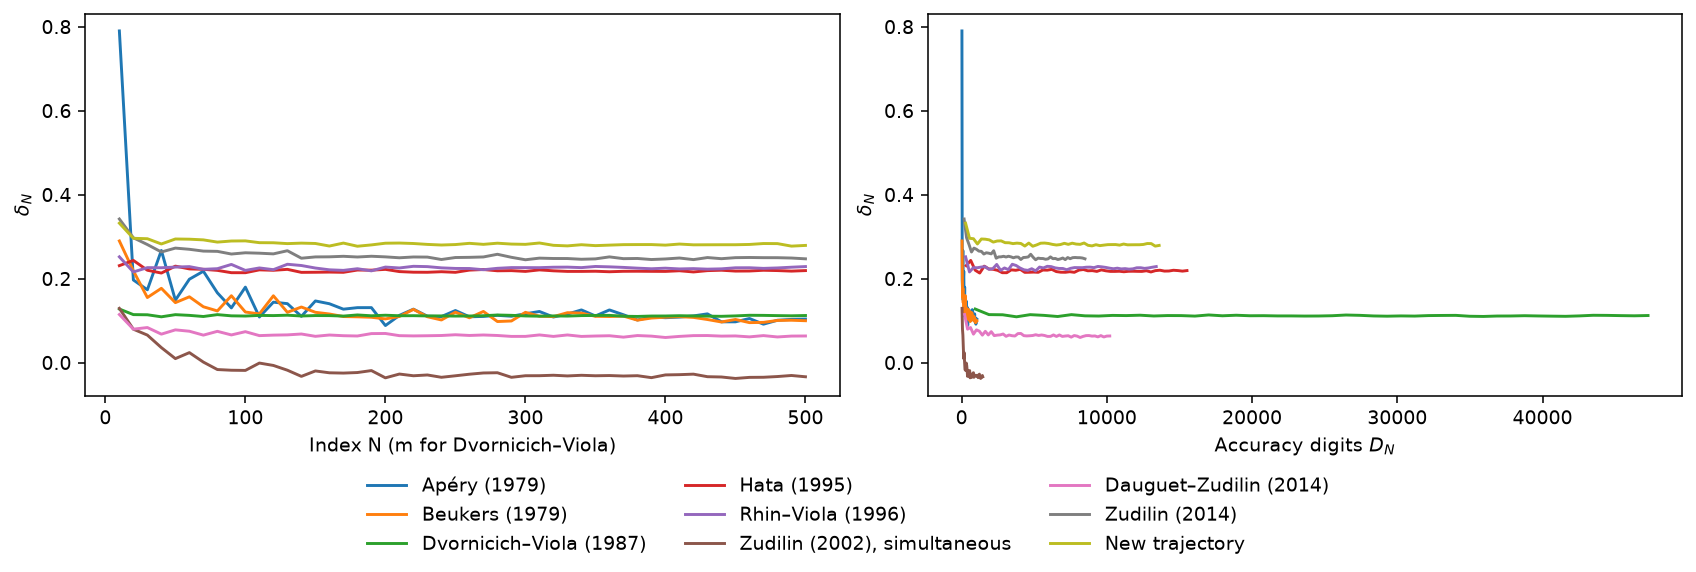

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N (m for Dvornicich–Viola)", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, frameon=False)
plt.show()

## Historical overview

Bounds are reference values; the last column contains only this run’s measurements.

In [29]:
bounds = {
    "Apéry (1979)": "11.85078…", "Beukers (1979)": "11.85078…",
    "Dvornicich–Viola (1987)": "10.0298", "Hata (1995)": "5.687",
    "Rhin–Viola (1996)": "5.441243", "Zudilin (2002), simultaneous": "Convergence only",
    "Dauguet–Zudilin (2014)": "Simultaneous s ≤ 6.770732145…",
    "Zudilin (2014)": "5.095412", "Giraudin (2026)": "5.0193784",
    "New trajectory": "4.58989684 (manuscript)",
}
rows = ["| Construction | Bound | Measured delta at index 500 |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    value = f"{results[name][1][-1]:.12f}" if name in results else "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Bound | Measured delta at index 500 |
|:--|:--|:--|
| Apéry (1979) | 11.85078… | 0.103550179820 |
| Beukers (1979) | 11.85078… | 0.099556310096 |
| Dvornicich–Viola (1987) | 10.0298 | 0.111941952821 |
| Hata (1995) | 5.687 | 0.218953712375 |
| Rhin–Viola (1996) | 5.441243 | 0.228507762157 |
| Zudilin (2002), simultaneous | Convergence only | -0.033960333442 |
| Dauguet–Zudilin (2014) | Simultaneous s ≤ 6.770732145… | 0.063210621068 |
| Zudilin (2014) | 5.095412 | 0.246952248284 |
| Giraudin (2026) | 5.0193784 | Not computed |
| New trajectory | 4.58989684 (manuscript) | 0.278885254360 |